# 02 - Model results and inference

Training is run with `python -m heartrisk.models.train` (also in CI). This notebook reviews what that session produced and shows how the packaged model is used for inference - the same `HeartRiskModel` wrapper the FastAPI service loads.

In [1]:
import json
import pandas as pd
from IPython.display import Image, display

from heartrisk.config import resolve
from heartrisk.models.predict import HeartRiskModel

pd.set_option('display.width', 140)

## 1. Model comparison

Three model families, each tuned with and without the engineered features (5-fold stratified CV on the training split; test = 20% hold-out).

In [2]:
summary = pd.read_csv(resolve('reports/model_comparison.csv'))
summary.round(3)

,run_name,cv_roc_auc,cv_roc_auc_std,cv_accuracy,cv_precision,cv_recall,cv_f1,test_roc_auc,test_accuracy,test_precision,test_recall,overfit_gap
0,logreg-eng,0.915,0.013,0.831,0.834,0.792,0.809,0.948,0.869,0.812,0.929,0.010
1,logreg-base,0.908,0.014,0.843,0.863,0.792,0.823,0.953,0.885,0.839,0.929,0.025
2,rf-eng,0.903,0.021,0.810,0.817,0.764,0.782,0.945,0.885,0.862,0.893,0.067
3,rf-base,0.900,0.026,0.822,0.831,0.774,0.797,0.950,0.918,0.897,0.929,0.064
4,gbm-eng,0.894,0.024,0.826,0.845,0.774,0.802,0.956,0.902,0.867,0.929,0.073
5,gbm-base,0.883,0.028,0.822,0.851,0.756,0.795,0.960,0.902,0.867,0.929,0.078


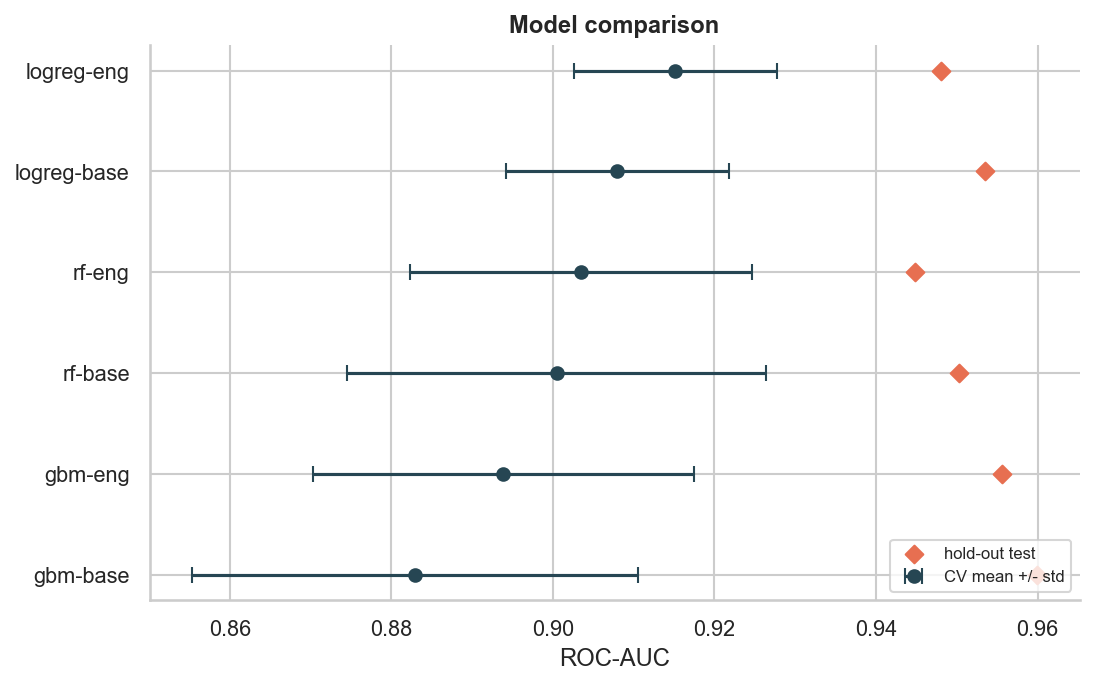

In [3]:
display(Image(filename=str(resolve('reports/figures/model/10_model_comparison.png')), width=650))

Logistic regression with the engineered features has the best and most stable CV ROC-AUC and the smallest train-CV gap, so it is the champion. The engineered features improve CV ROC-AUC for every model family:

In [4]:
s = summary.assign(model=summary.run_name.str.split('-').str[0],
                   features=summary.run_name.str.split('-').str[1])
s.pivot(index='model', columns='features', values='cv_roc_auc').assign(gain=lambda d: d['eng'] - d['base']).round(4)

features,base,eng,gain
model,,,
gbm,0.8829,0.8938,0.0109
logreg,0.9079,0.9152,0.0072
rf,0.9005,0.9035,0.0030


## 2. Champion on the hold-out set

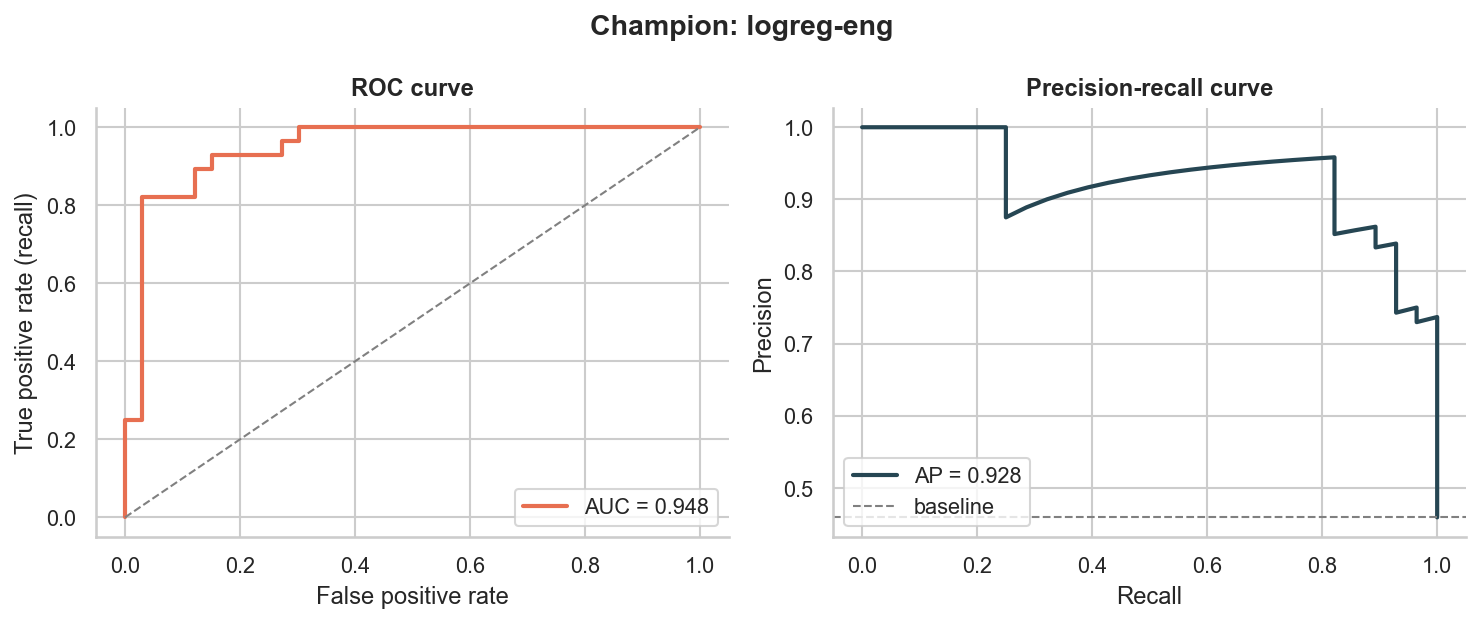

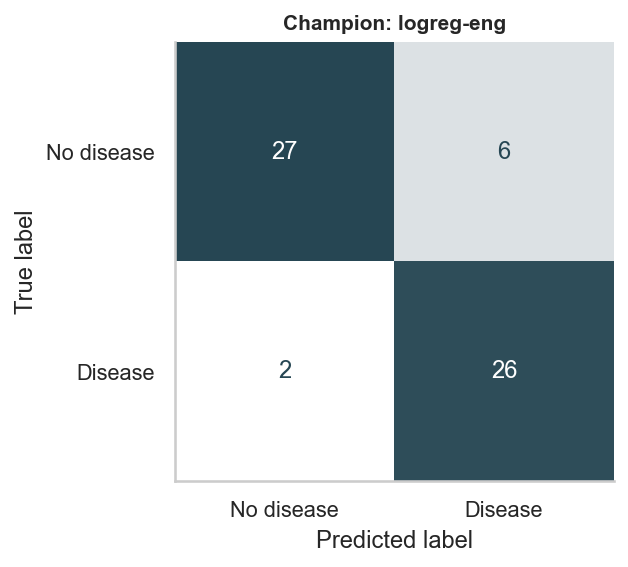

In [5]:
fig_dir = resolve('reports/figures/model')
display(Image(filename=str(fig_dir / '13_champion_roc_pr.png'), width=800))
display(Image(filename=str(fig_dir / '12_champion_confusion.png'), width=380))

## 3. Experiment tracking

Runs are logged to the local MLflow store (`mlflow.db`, created by `make train`).

In [6]:
import mlflow

db = resolve('mlflow.db')
if db.exists():
    mlflow.set_tracking_uri(f'sqlite:///{db}')
    runs = mlflow.search_runs(experiment_names=['cardiorisk-heart-disease'],
                              filter_string="tags.stage = 'tuning'",
                              order_by=['metrics.cv_roc_auc DESC'])
    display(runs[['tags.mlflow.runName', 'params.model_type', 'params.engineered_features',
                  'metrics.cv_roc_auc', 'metrics.test_roc_auc', 'metrics.test_recall']]
            .head(6).round(3))
else:
    print('No local MLflow store yet - run `make train` first.')

,tags.mlflow.runName,params.model_type,params.engineered_features,metrics.cv_roc_auc,metrics.test_roc_auc,metrics.test_recall
0,logreg-eng,logistic_regression,True,0.915,0.948,0.929
1,logreg-eng,logistic_regression,True,0.915,0.948,0.929
2,logreg-base,logistic_regression,False,0.908,0.953,0.929
3,logreg-base,logistic_regression,False,0.908,0.953,0.929
4,rf-eng,random_forest,True,0.903,0.945,0.893
5,rf-eng,random_forest,True,0.903,0.945,0.893


## 4. Inference with the packaged model

`models/` holds the full pipeline (features, preprocessing, model) plus metadata.

In [7]:
model = HeartRiskModel.load()
print('version :', model.version)
print('type    :', model.metadata['model_type'])
keys = ['cv_roc_auc', 'test_roc_auc', 'test_recall']
print('metrics :', {k: model.metadata['metrics'][k] for k in keys})

version : 2026.10.20.0521
type    : logistic_regression
metrics : {'cv_roc_auc': 0.9152, 'test_roc_auc': 0.9481, 'test_recall': 0.9286}


In [8]:
patients = json.loads(resolve('samples/patients.json').read_text())
results = model.predict(patients, explain=True)
cols = ['prediction', 'probability', 'confidence', 'risk_band']
pd.DataFrame(patients).join(pd.DataFrame(results)[cols])

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,prediction,probability,confidence,risk_band
0,41,0,2,130,204,0,2,172,0,1.4,1,0,3,0,0.0868,0.9132,low
1,67,1,4,160,286,0,2,108,1,1.5,2,3,3,1,0.9874,0.9874,high
2,57,1,3,150,168,0,0,174,0,1.6,1,0,3,0,0.1119,0.8881,low


Each prediction also explains itself - the three features that moved this patient's log-odds the most (coefficient x standardised value):

In [9]:
for p, r in zip(patients, results, strict=True):
    factors = ', '.join(f"{f['feature']} ({f['weight']:+.2f})" for f in r['top_factors'])
    who = f"age {p['age']}, sex {p['sex']}"
    print(f"{who}: {r['label']} p={r['probability']:.2f} -> {factors}")

age 41, sex 0: no_heart_disease p=0.09 -> age_x_male (-0.55), ca (-0.53), thal_3 (-0.51)
age 67, sex 1: heart_disease p=0.99 -> ca (+1.86), cp_4 (+0.62), thal_3 (-0.51)
age 57, sex 1: no_heart_disease p=0.11 -> ca (-0.53), thal_3 (-0.51), cp_3 (-0.42)


## 5. Same answer from the MLflow format

The MLflow copy of the model gives identical predictions, so either format can be served.

In [10]:
pyfunc = mlflow.pyfunc.load_model(str(resolve('models/mlflow_model')))
frame = pd.DataFrame(patients)[model.metadata['features']].astype(float)
print('MLflow  :', [int(x) for x in pyfunc.predict(frame)])
print('wrapper :', [r['prediction'] for r in results])

MLflow  : [0, 1, 0]
wrapper : [0, 1, 0]


## 6. Input validation

Missing fields are rejected rather than silently imputed (the API adds range checks on top).

In [11]:
try:
    model.predict([{k: v for k, v in patients[0].items() if k != 'thalach'}])
except ValueError as exc:
    print('rejected:', exc)

rejected: Missing required fields: ['thalach']
